## Урок 2

### Урок 2.1 Знакомство с `subprocess`

Ранее мы использовали `sys.exit()`, чтобы сообщить операционной системе результат работы программы

Теперь посмотрим на противоположную сторону: **как одна Python-программа может запустить другую и узнать, чем закончилась ее выполнение**

Для этого используется модуль `subprocess`

1. **Что делает `subprocess`?**

Представим, что у нас есть два файла:

``` python
# child.py

import sys

print("Начало работы")
sys.exit(3)

```

``` python
# main.py

import sys
import subprocess

result = subprocess.run(
    [sys.executable, "child.py"]
)
```

Когда мы вызываем `main.py` происходит следующее:

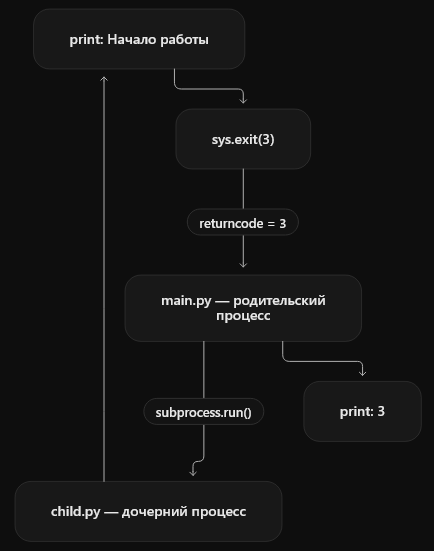

И вывод будет таким:

``` text
Начало работы
3
```

Нужно обратить внимание на то, что первое сообщение вывела дочерняя программа, а число `3` - родительская, прочитав `result.returncode`



2. **Что такое `returncode`?**

Когда мы выполняем:

``` python
result = subprocess.run(
    [sys.executable, "child.py"]
)
```

`subprocess.run()` дожидается завершения дочернего процесса и возвращает объект `CompletedProcess`

У него есть атрибут `returncode`, содержащий код завершения

Важная особенность: **ненулевой `returncode` сам по себе не вызывает исключение Python**. Позже будет описано как изменяется это поведение с помощью `check=True`


3. **А что, если нужно получить текст, который вывела программа?**

Для этого можно использовать параметры `capture_output=True` и `text=True`

``` python
result = subprocess.run(
    [sys.executable, "child.py"],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.returncode)
```

`capture_output=True` позволяет сохранить обычный вывод (`stdout`) и вывод ошибок (`stderr`) дочернего процесса, вместо того чтобы сразу показывать их в терминале

`text=True` позволяет получать этот вывод в виде строк Python



### Урок 2.2 `stdout`, `stderr` и обработка результатов


1. **Три стандартных потока процесса**

Когда операционная система запускает процесс, у него обычно есть три стандартных потока:

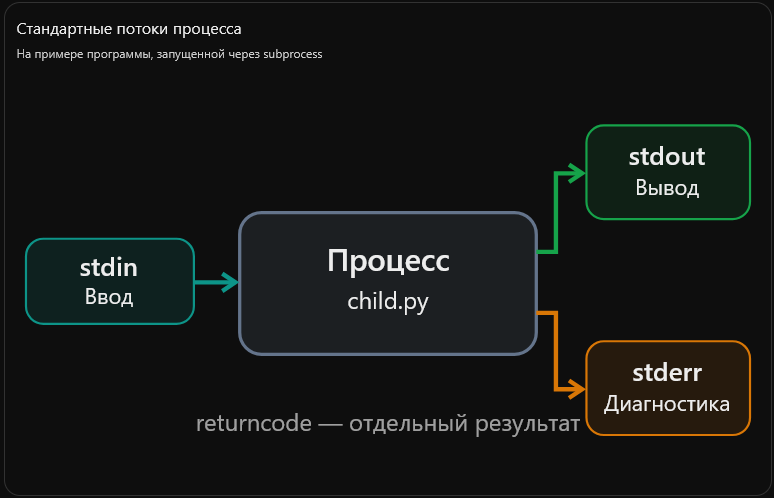

| Поток    | Назначение                                         |
|:---------|:---------------------------------------------------|
| `stdin`  | Передача данных в программу                        |
| `stdout` | Основной результат работы программы                |
| `stderr` | Ошибки, предупреждения и диагонстические сообщения |


Нужно обратить внимание на то, что `stderr` **не означает, что программа обязательно завершилась с ошибкой**

Например, программа может вывести предупреждение в `stderr`, а затем успешно завершиться с ошибкой `returncode=0`

И наоборот: программа может завершиться с `returncode=1`, ничего не записав в `stderr`

Поэтому в Harness Engineering нужны все ти характеристики результата: `stdout`, `stderr` и `returncode`

2. **Технический `std`**

В конце строки `stdout` и `stderr` при использовании с `print()` добавляет `\n`.

Например:
``` text
"Программа запущена\n"
```

или

``` text
"Что-то пошло не так\n"
```

Символ `\n` означает перевод строки. Функция `print()` по умолчанию добавляет его в конец вывода

Если нужно убрать завершающий перевод строки, можно использовать:

``` python
result.stdout.strip()
```

3. **Что такое `check=True`**

Теперь рассмотрим пример, который меняет поведение `subprocess.run()`

Раньше мы писали:

``` python
result = subprocess.run(
    [sys.executable, "child.py"],
    capture_output=True,
    text=True
)
```

Теперь добавим:

``` python
result = subprocess.run(
    [sys.executable, "child.py"],
    capture_output=True,
    text=True,
    check=True
)
```

При `check=True` Python автоматически проверяет код завершения дочернего процесса

Если `returncode != 0`, возникает исключение `subprocess.CalledProcessError`

Сравнение поведения:

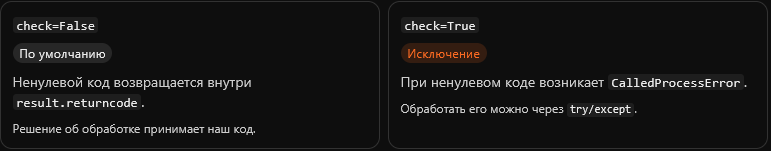


### Урок 2.3. Таймауты в `subprocess`

Теперь рассмотрим еще одну проблему, с которой обязательно сталкиваются при разработке Harness

Представим, что наш агент запустил тесты проекта, но один из тестов завис и не завершается

Если использовать:

``` python
subprocess.rub(
    [sys.executable, "test.py"]
)
```

то родительская программа будет ожидать завершения дочернего процесса без установленного нами ограничения времени

Агент может надолго застрять на одной команде

Для решения этой проблемы у `subprocess.run()` есть параметр `timeout`

1. **Параметр `timeout`**

``` python
result = subprocess.run(
    [sys.executable, "test.py"],
    timeout=5
)
```

Здесь `timeout=5` означает, что мы разрешаем дочернему процессу выполняться не более 5 секунд после его запуска

Если процесс не завершится за отведенное время, возникает исключение:

``` python
subprocess.TimeoutExpired
```

При таком исключении `subprocess.run()` принудительно завершает дочерний процесс и дожидается его остановки


2. **Три разных ситуации**

Теперь мы знаем три принципиально разных исхода запуска команды

| Ситуация                                     | Что происходит                          |
|:---------------------------------------------|:----------------------------------------|
| Программа завершилась с кодом `0`            | Успешное завершение                     |
| Программа завершилась с ненулевым кодом      | `CalledProcessError`, если `check=True` |
| Программа не завершилась за отведенное время | `TimeoutExpired` независимо от `check`  |


3. **Как обработать таймаут**

``` python
import subprocess
import sys

try:
    result = subprocess.run(
        [sys.executable, "run.py"],
        timeout=5,
        capture_output=True,
        text=True
    )
except subprocess.TimeoutExpired:
    print("Программа выполнялась слишком долго")
```

Нужно обратить внимание: при таймауте мы не получим обычный `result`, потому что `subprocess.run()` завершится исключением

Это не то же самое, что получить ненулевой `returncode`


### Урок 2.4. Создаем собственный Process Runner

Вспомним, зачем вообще нужен `Process Runner`

Представим, что LLM-агент получил задачу:

> Проверь, проходят ли тесты проекта

Агент решает выполнить:

``` bash
python -m pytest
```

Но непосредственно запускать программу должна не LLM, а Python-система - Harness

Именно Process Runner отвечает за запуск команды, ожидание результата, сбор вывода и обработку ошибок


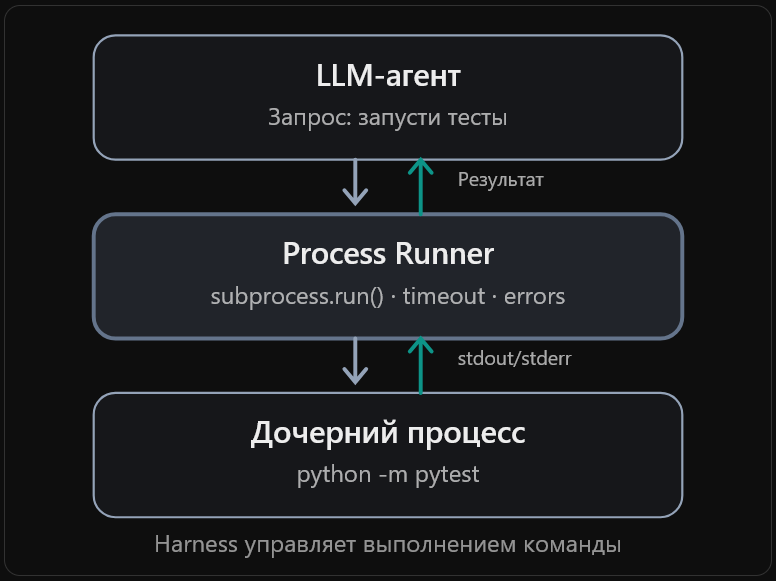


1. **Зачем нам отдельная функция**

Мы могли бы каждый раз писать:

``` python
subprocess.run(...)
```

Но тогда в разных частях Harness пришлось бы повторять код запуска команд и обработки ошибок

Гораздо удобнее создать одну функцию:

``` python
def run_process(
    argv: list[str],
    timeout_s: float
) -> dict:
    ...
```

Она будет принимать команду, запускать ее и возвращать структурированный результат

Например, при успешном выполнении:

``` python
{
    "status": "success",
    "returncode": 0,
    "stdout": "Test passed\n",
    "stderr": ""
}
```


А если команда завершилась с кодом `7`:

``` python
{
    "status": "failed",
    "returncode": 7,
    "stdout": "",
    "stderr": "Tests failed\n"
}
```

Важное преимущество: вызывающему коду не нужно знать, как именно мы запускали команду. Он получает стандартизированный результат



### Урок 2.5. Валидация аргументов

**Обработка некорректных входных данных**

До сих пор мы предполагали, что вызывающий код всегда передает корректные значения

Но что произойдет, если LLM-агент вызовет:

``` python
run_process([], 5)
```

Или:

```python
run_process(
    [sys.executable, "-c", "print(''Hello')"],
)
```

В первом случае мы пытаемся запустить пустую команду

Во втором задаем отрицательное время ожидания

Оба случая нужно обрабатывать до вызова `subprocess.run()`


**2.5.1. Что такое валидация?**

**Валидация** - проверка того, соответствуют ли входные данные требованиям нашей программы

Например:

``` python
def square_root(x:float) -> float:
    if x < 0:
        raise ValueError("x должен быть неотрицательным")

    return x ** 0.5
```

Здесь мы проверяем аргумент до выполнения основной операции

Нужно обратить внимание на различие между `raise` и `sys.exit()`:

- `raise ValueError(...)` сообщает вызывающему коду о некорректном аргументе
- `sys.exit(...)` инициирует завершение Python-программы

Для функции `run_process()` предпочтительнее использовать `raise`, потому что это компонент Harness, а не самостоятельная программа, которая должна завершиться при любой проблеме